# DTSA 5798: Classifying Health/Wellness Articles for Theragun's Marketing Team

## Purpose/Motivation:

The purpose of this project is to build a deep learning algorithm that predicts whether online articles are health and wellness-related or not. The model will be used by Theragun's marketing team to ensure that they are advertising to the correct target audience (people who are interested in health, wellness, fitness ect).


In Lab 1, we analyzed and preprocessed the News Category Training Dataset using Pandas. We first combined the "headline" and "short_description" columns into one column called "combined_column". Combining these two text columns ensures that our LLM would correctly process the text later on.

I also added an additional column, ("healthy"), to track whether an article had to do with health/wellness or not. If the article included health/wellness content then a 1 was added, and if it was unrelated, then a 0 was added.
Creating this column will ultimately help Theraguns marketing Team later on when sending out targeted marketing campaigns.

For this final project, I will use the entire "Healthy Living" article category and combine it with the "Wellness" category to have a labeled training set of roughly 24,521 articles. I will then randomly sample 24,521 other articles that from other categories to balance dataset. This will serve as the not healthy (o) training data for the model to learn from.
Combining the Healthy Living and Wellness categories automatically puts our model in a great position for beating Dr. Vargos models performance, as well a the inclass model.

The inclass model used 1,000 health/wellness articles and 1,000 non-related articles. And had about an 81% accuracy rating. From changing the training data from 2,000 entries to roughly 50,000 articles I am confident that the score will be increased.


For this model I will be using the the transformer distilbert which is a  pre-trained language model. This is also the same transformer we utilized in class. I will also change the learning speed hyperparameter to the optimal learning rate, and use k-train, tensorflow and keras packages to train the learning model.

## Data Citation:

1. Misra, Rishabh. "News Category Dataset." arXiv preprint arXiv:2209.11429 (2022).
2. Misra, Rishabh and Jigyasa Grover. "Sculpting Data for ML: The first act of Machine Learning." ISBN 9798585463570 (2021).
https://www.kaggle.com/datasets/rmisra/news-category-dataset

## Dataset Description:

The News Category Dataset contains 210,294 news articles that were published on HuffPost between 2012 to 2022. There are 42 different news categories in the dataset. Each entry contains the category the article was published in, the headline of the article, the authors name, a short description of the article and the original publication date.


## Importing Data and Packages:

In [ ]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
!pip install -q transformers==4.35.0
!pip -q install -U tf-keras ktrain
!pip uninstall numpy -y
!pip install numpy==1.26.4 -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.1/123.1 kB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 149.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 132.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.0/295.0 kB 33.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 5.50.0 requires huggingface-hub<2.0,>=0.33.5, but you have huggingface-hub 0.17.3 which is incompatible.
gradio-client 1.14.0 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 0.17.3 which is incompatible.
peft 0.18.1 requires huggingface_hub>=0.25.0, but you have huggingface-hub 0.17.3 which is incompatible.
sentence-transformers 5.3.0 requires huggingface-hub>=0.20.0, but you have huggingface-hub 0.17.3 which is incompatible.
sentence-transformers 5.3.0 requires transformers<

In [ ]:
# import os
# os.environ["TF_USE_LEGACY_KERAS"] = "1"
# import ktrain
# import pandas as pd
# import numpy as np
# from google.colab import drive
# drive.mount('/content/drive')
# print("All imports successful!")
# print(f"Numpy version: {np.__version__}")

In [ ]:
import keras
import tensorflow as tf

if not hasattr(keras.backend, 'set_value'):
    keras.backend.set_value = lambda x, v: x.assign(v)
    print("Patch 1 applied: set_value")

if not hasattr(keras.backend, 'get_value'):
    keras.backend.get_value = lambda x: x.numpy()
    print("Patch 2 applied: get_value")

if not hasattr(keras.backend, 'is_tensor'):
    keras.backend.is_tensor = tf.is_tensor
    print("Patch 3 applied: is_tensor")

if not hasattr(keras.backend, 'int_shape'):
    keras.backend.int_shape = lambda x: x.shape
    print("Patch 4 applied: int_shape")

if not hasattr(keras.backend, 'batch_set_value'):
    keras.backend.batch_set_value = lambda tuples: [x.assign(v) for x, v in tuples]
    print("Patch 5 applied: batch_set_value")

print("All patches applied!")

ValueError: numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
articles = pd.read_json("/content/drive/MyDrive/Colab_Notebooks/Supervised_Text_ML/News_Category_Training_Data.json")
print(articles.shape)
print(articles.head())

(200853, 6)
        category                                           headline  \
0          CRIME  There Were 2 Mass Shootings In Texas Last Week...   
1  ENTERTAINMENT  Will Smith Joins Diplo And Nicky Jam For The 2...   
2  ENTERTAINMENT    Hugh Grant Marries For The First Time At Age 57   
3  ENTERTAINMENT  Jim Carrey Blasts 'Castrato' Adam Schiff And D...   
4  ENTERTAINMENT  Julianna Margulies Uses Donald Trump Poop Bags...   

           authors                                               link  \
0  Melissa Jeltsen  https://www.huffingtonpost.com/entry/texas-ama...   
1    Andy McDonald  https://www.huffingtonpost.com/entry/will-smit...   
2       Ron Dicker  https://www.huffingtonpost.com/entry/hugh-gran...   
3       Ron Dicker  https://www.huffingtonpost.com/entry/jim-carre...   
4       Ron Dicker  https://www.huffingtonpost.com/entry/julianna-...   

                                   short_description       date  
0  She left her husband. He killed their children... 201

### Exploratory Data Analysis:

In [ ]:
articles.head()

,category,headline,authors,link,short_description,date
0,CRIME,There Were 2 Mass Shootings In Texas Last Week...,Melissa Jeltsen,https://www.huffingtonpost.com/entry/texas-ama...,She left her husband. He killed their children...,2018-05-26
1,ENTERTAINMENT,Will Smith Joins Diplo And Nicky Jam For The 2...,Andy McDonald,https://www.huffingtonpost.com/entry/will-smit...,Of course it has a song.,2018-05-26
2,ENTERTAINMENT,Hugh Grant Marries For The First Time At Age 57,Ron Dicker,https://www.huffingtonpost.com/entry/hugh-gran...,The actor and his longtime girlfriend Anna Ebe...,2018-05-26
3,ENTERTAINMENT,Jim Carrey Blasts 'Castrato' Adam Schiff And D...,Ron Dicker,https://www.huffingtonpost.com/entry/jim-carre...,The actor gives Dems an ass-kicking for not fi...,2018-05-26
4,ENTERTAINMENT,Julianna Margulies Uses Donald Trump Poop Bags...,Ron Dicker,https://www.huffingtonpost.com/entry/julianna-...,"The ""Dietland"" actress said using the bags is ...",2018-05-26


In [ ]:
# Reviewing total articles in each category
print(articles['category'].value_counts())

category
POLITICS          32739
WELLNESS          17827
ENTERTAINMENT     16058
TRAVEL             9887
STYLE & BEAUTY     9649
PARENTING          8677
HEALTHY LIVING     6694
QUEER VOICES       6314
FOOD & DRINK       6226
BUSINESS           5937
COMEDY             5175
SPORTS             4884
BLACK VOICES       4528
HOME & LIVING      4195
PARENTS            3955
THE WORLDPOST      3664
WEDDINGS           3651
WOMEN              3490
IMPACT             3459
DIVORCE            3426
CRIME              3405
MEDIA              2815
WEIRD NEWS         2670
GREEN              2622
WORLDPOST          2579
RELIGION           2556
STYLE              2254
SCIENCE            2178
WORLD NEWS         2177
TASTE              2096
TECH               2082
MONEY              1707
ARTS               1509
FIFTY              1401
GOOD NEWS          1398
ARTS & CULTURE     1339
ENVIRONMENT        1323
COLLEGE            1144
LATINO VOICES      1129
CULTURE & ARTS     1030
EDUCATION          1004
Name: c

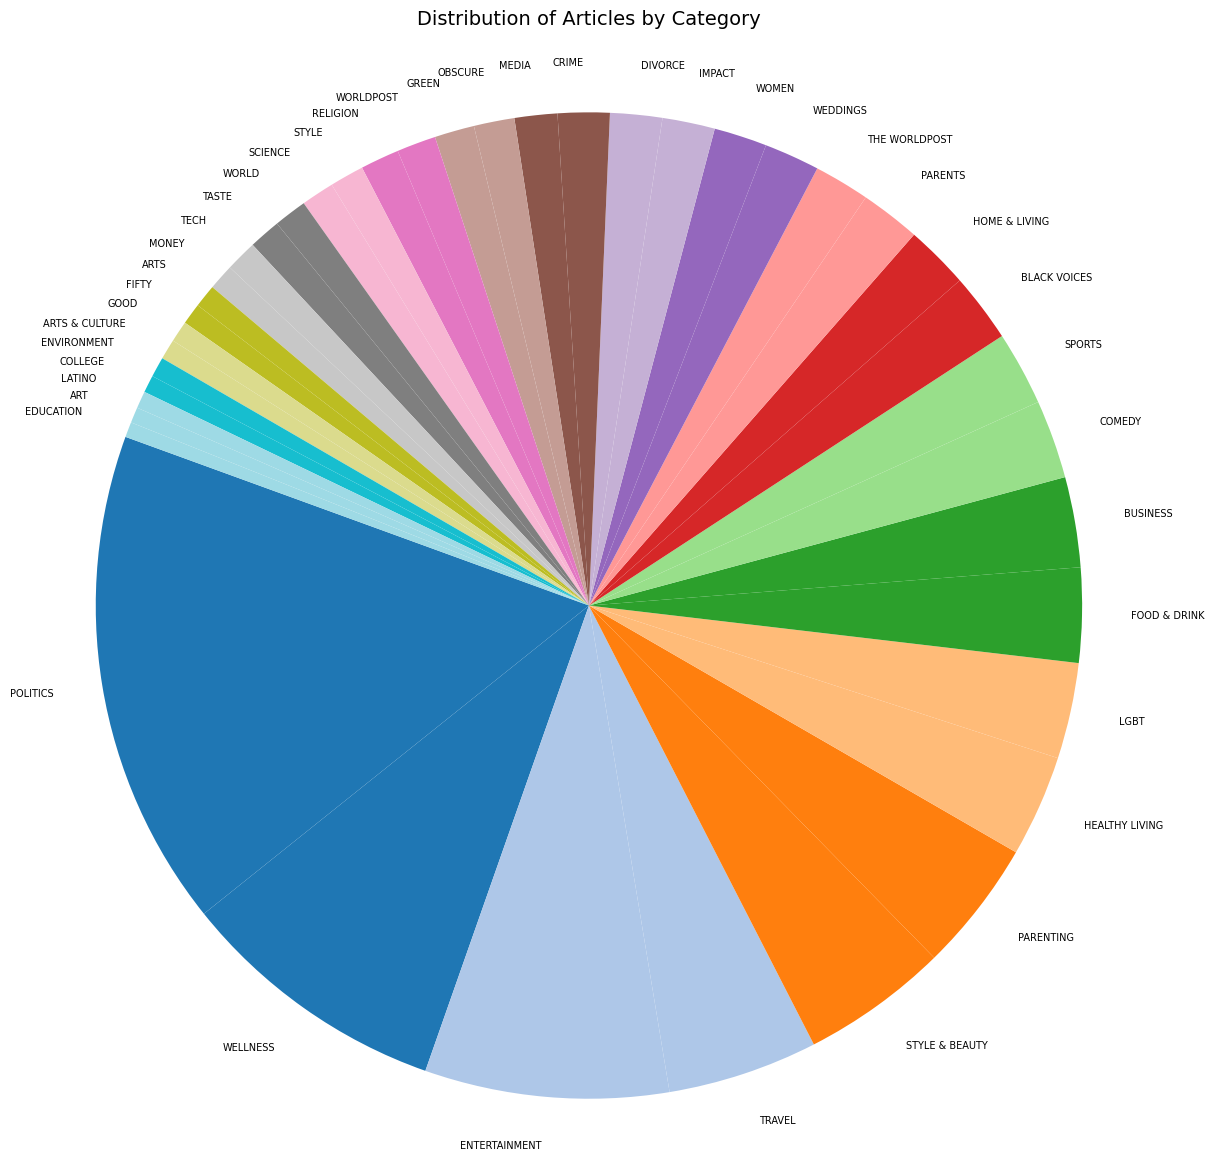

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

category_counts = articles['category'].value_counts()

# Rename categories
category_counts.index = category_counts.index.str.replace('LATINO VOICES', 'LATINO') \
    .str.replace('CULTURE & ARTS', 'ART') \
    .str.replace('GOOD NEWS', 'GOOD') \
    .str.replace('QUEER VOICES', 'LGBT') \
    .str.replace('WEIRD NEWS', 'OBSCURE') \
    .str.replace('WORLD NEWS', 'WORLD')

colors = plt.cm.tab20(np.linspace(0, 1, len(category_counts)))

plt.figure(figsize=(14, 14))
plt.pie(category_counts, labels=category_counts.index, startangle=160,
        colors=colors, textprops={'fontsize': 7}, labeldistance=1.1)
plt.title('Distribution of Articles by Category', fontsize=14, pad=30)
plt.axis('equal')
plt.show()

### Data Preprocessing:

The articles headline and short description columns were first merged to ensure the LLM could process the information later on. Another column named healthy was added to the dataset to serve as a binary tracker of what articles were related to health/wellness or not. A one in the column indicated that the article was relating to health/wellness and a 0 indicated that it was not. In Lab 2 we used 1,000 articles known to be health/wellness related from the "Healthy Living" category. We then balanced this training dataset with 1,000 articles that were not in that category.

For this final project, I will use the entire "Healthy Living" category and combine it with the "Wellness" column to have a labeled training set of roughly 24,521 articles. This will serve as the labeled articles that have 1. I will then use a random sample of 24,521 articles that are from various other categories not related to health and wellness. This will serve as the not healthy training data for the model to learn from.

In [ ]:
# Combine Columns
articles['combined_text'] = articles['headline'] + ' ' + articles['short_description']

# Add 0 to Healthy Living articles and 0 to all other entries
articles['healthy'] = np.where((articles['category'] == 'HEALTHY LIVING'), 1, 0)

In [ ]:
# Create a balanced dataset for model training
# Create a balanced dataset for model training
articles['healthy'] = np.where(
    (articles['category'] == 'HEALTHY LIVING') |
    (articles['category'] == 'WELLNESS'), 1, 0)

sample_amount = len(articles[articles["healthy"] == 1])

healthy = articles[articles['healthy'] == 1]
not_healthy = articles[articles['healthy'] == 0].sample(n=sample_amount)

article_sample = pd.concat([healthy, not_healthy])

article_sample.describe()

,date,healthy
count,49042,49042.000000
mean,2014-08-05 11:40:33.718037504,0.500000
min,2012-01-28 00:00:00,0.000000
25%,2013-02-23 00:00:00,0.000000
50%,2014-03-08 00:00:00,0.500000
75%,2015-12-21 00:00:00,1.000000
max,2018-05-26 00:00:00,1.000000
std,NaN,0.500005


In [ ]:
# Inspect unhealthy training articles (chosen with random sampling)
print(not_healthy['category'].value_counts())

category
POLITICS          4483
ENTERTAINMENT     2285
TRAVEL            1415
STYLE & BEAUTY    1373
PARENTING         1195
QUEER VOICES       911
FOOD & DRINK       831
BUSINESS           825
COMEDY             713
BLACK VOICES       663
SPORTS             655
HOME & LIVING      571
PARENTS            546
IMPACT             516
CRIME              510
THE WORLDPOST      510
WOMEN              499
DIVORCE            484
WEDDINGS           455
MEDIA              420
WEIRD NEWS         352
WORLDPOST          346
GREEN              334
RELIGION           324
STYLE              307
SCIENCE            307
WORLD NEWS         302
TECH               297
TASTE              286
MONEY              227
ARTS               215
GOOD NEWS          200
ENVIRONMENT        198
ARTS & CULTURE     183
FIFTY              176
LATINO VOICES      165
COLLEGE            165
EDUCATION          149
CULTURE & ARTS     128
Name: count, dtype: int64


### Model Building:

In Lab 2 we used the distilbert-base-uncased transformer model. In that model I used a balanced dataset of 2,000 training articles (1,000 healh/wellness and 1,000, not-related). This final model had about an 81% accurately in differentiating between health/wellness articles and non-related articles. For this final project I will use the roberta-base transformer, which is another language model that is pretrained on English-language grammer, meaning of words, and context of words in sentences.
The roberta-base transformer is known for performing well on large datasets, so I am hopeful that the models performance will improve from lab 2.


In [ ]:
target_names = ['NOT HEALTHY', 'HEALTHY & WELLNESS']

In [ ]:
import keras
import tensorflow as tf

# Patch 1: set_value
if not hasattr(keras.backend, 'set_value'):
    keras.backend.set_value = lambda x, v: x.assign(v)
    print("Patch 1 applied: set_value")

# Patch 2: get_value
if not hasattr(keras.backend, 'get_value'):
    keras.backend.get_value = lambda x: x.numpy()
    print("Patch 2 applied: get_value")

# Patch 3: is_tensor
if not hasattr(keras.backend, 'is_tensor'):
    keras.backend.is_tensor = tf.is_tensor
    print("Patch 3 applied: is_tensor")

# Patch 4: function
if not hasattr(keras.backend, 'function'):
    keras.backend.function = lambda inputs, outputs: outputs
    print("Patch 4 applied: function")

print("All patches applied!")

Patch 4 applied: function
All patches applied!


In [ ]:
# Loading the language model transformer for additional speed, accuracy and knowledge
train, val, preprocess = ktrain.text.texts_from_df(
    article_sample,
    "combined_text",
    label_columns=["healthy"],
    val_df=None,
    max_features=20000,
    maxlen=512,
    val_pct=0.1,
    ngram_range=1,
    preprocess_mode="distilbert",
    verbose=1
)

['not_healthy', 'healthy']
        not_healthy  healthy
129839          0.0      1.0
152547          1.0      0.0
73695           1.0      0.0
100689          1.0      0.0
160272          0.0      1.0
['not_healthy', 'healthy']
        not_healthy  healthy
181642          0.0      1.0
121621          0.0      1.0
200592          1.0      0.0
132911          0.0      1.0
199664          1.0      0.0


preprocessing train...
language: en
train sequence lengths:
	mean : 32
	95percentile : 58
	99percentile : 68


<div></div>

Is Multi-Label? False
preprocessing test...
language: en
test sequence lengths:
	mean : 32
	95percentile : 58
	99percentile : 67


<div></div>

In [ ]:
model = preprocess.get_classifier()
learner = ktrain.get_learner(model, train_data=train, val_data=val, batch_size=16)

Testing Learning Rates:



simulating training for different learning rates... this may take a few moments...
Epoch 1/6
2758/2758 [==============================] - 1222s 435ms/step - loss: 0.5029 - accuracy: 0.7814
Epoch 2/6
2758/2758 [==============================] - 1212s 439ms/step - loss: 0.2404 - accuracy: 0.9067
Epoch 3/6
2758/2758 [==============================] - 1210s 439ms/step - loss: 0.4063 - accuracy: 0.7649
Epoch 4/6
2758/2758 [==============================] - 911s 330ms/step - loss: 0.8146 - accuracy: 0.5023


done.
Please invoke the Learner.lr_plot() method to visually inspect the loss plot to help identify the maximal learning rate associated with falling loss.


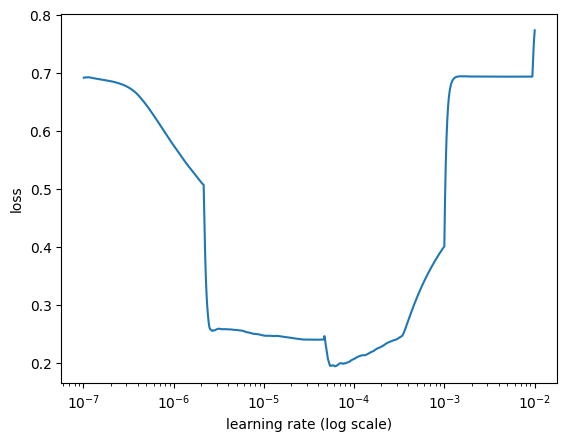

In [ ]:
learner.lr_find(max_epochs=6)
learner.lr_plot()

In [ ]:
history = learner.autofit(
    2e-5,
    checkpoint_folder='checkpoint',
    epochs=10,
    early_stopping=True
)



begin training using triangular learning rate policy with max lr of 2e-05...
Epoch 1/10
2759/2759 [==============================] - 1235s 441ms/step - loss: 0.2434 - accuracy: 0.9027 - val_loss: 0.2026 - val_accuracy: 0.9217
Epoch 2/10
2759/2759 [==============================] - 1214s 440ms/step - loss: 0.1521 - accuracy: 0.9429 - val_loss: 0.2068 - val_accuracy: 0.9205
Epoch 2: early stopping
Restoring model weights from the end of the best epoch: 1.
Weights from best epoch have been loaded into model.


In [ ]:
predictor = ktrain.get_predictor(learner.model, preproc=preprocess)

In [ ]:
predictor.save('/content/drive/MyDrive/Colab_Notebooks/Supervised_Text_ML/healthy_predictor')

In [ ]:
validation = learner.validate(val_data=val, print_report=True)

## Results and Conclusion:

Overall the model performed fairly well and even outperformed Dr. Vargo's model as well as the class model. The class model had about an 81% accuracy and the model above is performing at about a 92% aaccuracy.
Based off our valadation graph above we can see that it accurately classified health related content about 90% of the time and non-health related content about 93% of the time.
The recall scores indicate the model misclassified articles as health related about 10% of the time and misclassified articles as non-health related about 7% of the time. This is a strong result for marketing related projects and can be used for theraguns marketing team. For other projects in healthcare we may want to aim for different recall and accuracy values depending on the case.

This model can possibly be improved by changing other hyperparameters beyond training data, and learning rate. For example the batch size, or number of articles the model processes at once and allowing the model to run 15 different epochs to determine if the model needs more time to adjust.
